# PHẦN 1 — Bài 1 (Trang 15–17): Khảo sát và Tiền xử lý dữ liệu Titanic

- **Sinh viên thực hiện**: Dương Đại Phát – MSSV: `6451071058` – Lớp: `CQ.64.CNTT`
- **Nguồn dữ liệu**: `titanic.csv` (Google Drive Folder: https://drive.google.com/drive/folders/1rv5SiO5zFlU-cyEXul09OpCvTXrdjG1m?usp=sharing, File ID: `1TCnJqaowkv0caJTJrmjoqb0AB2bMvgxP`)
- **Mục tiêu**: Thực hiện đầy đủ 8 yêu cầu lập trình (1–8) theo tài liệu hướng dẫn trang 15–28.

## Khởi tạo môi trường và tải dữ liệu (Colab-ready)

In [1]:
print("Dương Đại Phát - 6451071058")
import os
import re
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 120

DATA_FILE = "titanic.csv"
DRIVE_ID = "1TCnJqaowkv0caJTJrmjoqb0AB2bMvgxP"

if os.path.exists(os.path.join("datasets", DATA_FILE)):
    DATA_PATH = os.path.join("datasets", DATA_FILE)
elif os.path.exists(DATA_FILE):
    DATA_PATH = DATA_FILE
else:
    try:
        import gdown
    except ImportError:
        import subprocess, sys
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown"])
        import gdown
    gdown.download(f"https://drive.google.com/uc?id={DRIVE_ID}", DATA_FILE, quiet=False)
    DATA_PATH = DATA_FILE

print("Đường dẫn dữ liệu:", DATA_PATH)

Dương Đại Phát - 6451071058


Đường dẫn dữ liệu: datasets\titanic.csv


## Yêu cầu 1: Nhập dữ liệu và thống kê những thông tin cơ bản của các thuộc tính

In [2]:
print("Dương Đại Phát - 6451071058")
df = pd.read_csv(DATA_PATH, dtype={"age": np.float64, "sibsp": np.int64, "parch": np.int64})
print(f"Kích thước tập dữ liệu: {df.shape[0]} dòng x {df.shape[1]} cột")
display(df.head(12))

Dương Đại Phát - 6451071058
Kích thước tập dữ liệu: 1309 dòng x 14 cột


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
5,1,1,"Anderson, Mr. Harry",male,48.0000,0,0,19952,26.5500,E12,S,3,NaN,"New York, NY"
6,1,1,"Andrews, Miss. Kornelia Theodosia",female,63.0000,1,0,13502,77.9583,D7,S,10,NaN,"Hudson, NY"
7,1,0,"Andrews, Mr. Thomas Jr",male,39.0000,0,0,112050,0.0000,A36,S,NaN,NaN,"Belfast, NI"
8,1,1,"Appleton, Mrs. Edward Dale (Charlotte Lamson)",female,53.0000,2,0,11769,51.4792,C101,S,D,NaN,"Bayside, Queens, NY"
9,1,0,"Artagaveytia, Mr. Ramon",male,71.0000,0,0,PC 17609,49.5042,NaN,C,NaN,22.0,"Montevideo, Uruguay"


In [3]:
print("Dương Đại Phát - 6451071058")
print("=== THÔNG TIN CẤU TRÚC DỮ LIỆU (df.info) ===")
df.info()
print("\n=== THỐNG KÊ MÔ TẢ CÁC THUỘC TÍNH SỐ (df.describe) ===")
display(df.describe())
print("\n=== THỐNG KÊ MÔ TẢ CÁC THUỘC TÍNH PHÂN LOẠI / CHUỖI ===")
display(df.describe(include=["object"]))

Dương Đại Phát - 6451071058
=== THÔNG TIN CẤU TRÚC DỮ LIỆU (df.info) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   object 
 3   sex        1309 non-null   object 
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   object 
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    object 
 10  embarked   1307 non-null   object 
 11  boat       486 non-null    object 
 12  body       121 non-null    float64
 13  home.dest  745 non-null    object 
dtypes: float64(3), int64(4), object(7)
memory usage: 143.3+ KB

=== THỐNG KÊ MÔ TẢ CÁC THUỘC TÍNH SỐ (df.describe) ===


,pclass,survived,age,sibsp,parch,fare,body
count,1309.000000,1309.000000,1046.000000,1309.000000,1309.000000,1308.000000,121.000000
mean,2.294882,0.381971,29.881135,0.498854,0.385027,33.295479,160.809917
std,0.837836,0.486055,14.413500,1.041658,0.865560,51.758668,97.696922
min,1.000000,0.000000,0.166700,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,21.000000,0.000000,0.000000,7.895800,72.000000
50%,3.000000,0.000000,28.000000,0.000000,0.000000,14.454200,155.000000
75%,3.000000,1.000000,39.000000,1.000000,0.000000,31.275000,256.000000
max,3.000000,1.000000,80.000000,8.000000,9.000000,512.329200,328.000000



=== THỐNG KÊ MÔ TẢ CÁC THUỘC TÍNH PHÂN LOẠI / CHUỖI ===


,name,sex,ticket,cabin,embarked,boat,home.dest
count,1309,1309,1309,295,1307,486,745
unique,1307,2,929,186,3,27,369
top,"Connolly, Miss. Kate",male,CA. 2343,C23 C25 C27,S,13,"New York, NY"
freq,2,843,11,6,914,39,64


**Nhận xét (Yêu cầu 1):**
- Tập dữ liệu Titanic đầy đủ gồm **1.309 hành khách** và **14 thuộc tính** (`pclass`, `survived`, `name`, `sex`, `age`, `sibsp`, `parch`, `ticket`, `fare`, `cabin`, `embarked`, `boat`, `body`, `home.dest`).
- Thuộc tính quyết định là `survived` (`0`: không sống sót, `1`: sống sót) với tỷ lệ sống sót trung bình toàn tàu là **38,20%** (`mean = 0.381971`).
- Tuổi (`age`) dao động từ **0,1667** đến **80** tuổi (trung bình ~**29,88** tuổi); giá vé (`fare`) dao động từ **0** đến **512,3292** (trung bình ~**33,30**, trung vị **14,4542** – phân phối lệch phải mạnh).

## Yêu cầu 2: Liệt kê danh sách 5 thuộc tính có số lượng giá trị rỗng nhiều nhất

In [4]:
print("Dương Đại Phát - 6451071058")
total = df.isnull().sum().sort_values(ascending=False)
percent_1 = df.isnull().sum() / df.isnull().count() * 100
percent_2 = round(percent_1, 1).sort_values(ascending=False)
missing_data = pd.concat([total, percent_2], axis=1, keys=["Total", "%"])

print("Top 5 thuộc tính có số lượng giá trị rỗng nhiều nhất:")
display(missing_data.head(5))
print("\nCác thuộc tính còn lại có giá trị rỗng (> 0):")
display(missing_data[missing_data["Total"] > 0])

Dương Đại Phát - 6451071058
Top 5 thuộc tính có số lượng giá trị rỗng nhiều nhất:


,Total,%
body,1188,90.8
cabin,1014,77.5
boat,823,62.9
home.dest,564,43.1
age,263,20.1



Các thuộc tính còn lại có giá trị rỗng (> 0):


,Total,%
body,1188,90.8
cabin,1014,77.5
boat,823,62.9
home.dest,564,43.1
age,263,20.1
embarked,2,0.2
fare,1,0.1


**Nhận xét (Yêu cầu 2):**
- 5 thuộc tính thiếu dữ liệu nhiều nhất là:
  1. `body`: **1.188** giá trị rỗng (**90,8%**)
  2. `cabin`: **1.014** giá trị rỗng (**77,5%**)
  3. `boat`: **823** giá trị rỗng (**62,9%**)
  4. `home.dest`: **564** giá trị rỗng (**43,1%**)
  5. `age`: **263** giá trị rỗng (**20,1%**)
- Ngoài ra còn `embarked` thiếu **2** dòng (**0,2%**) và `fare` thiếu **1** dòng (**0,1%**).

## Yêu cầu 3: Vẽ biểu đồ khảo sát sự liên quan giữa Độ tuổi (`age`), Giới tính (`sex`) và khả năng sống sót (`survived`)

Dương Đại Phát - 6451071058


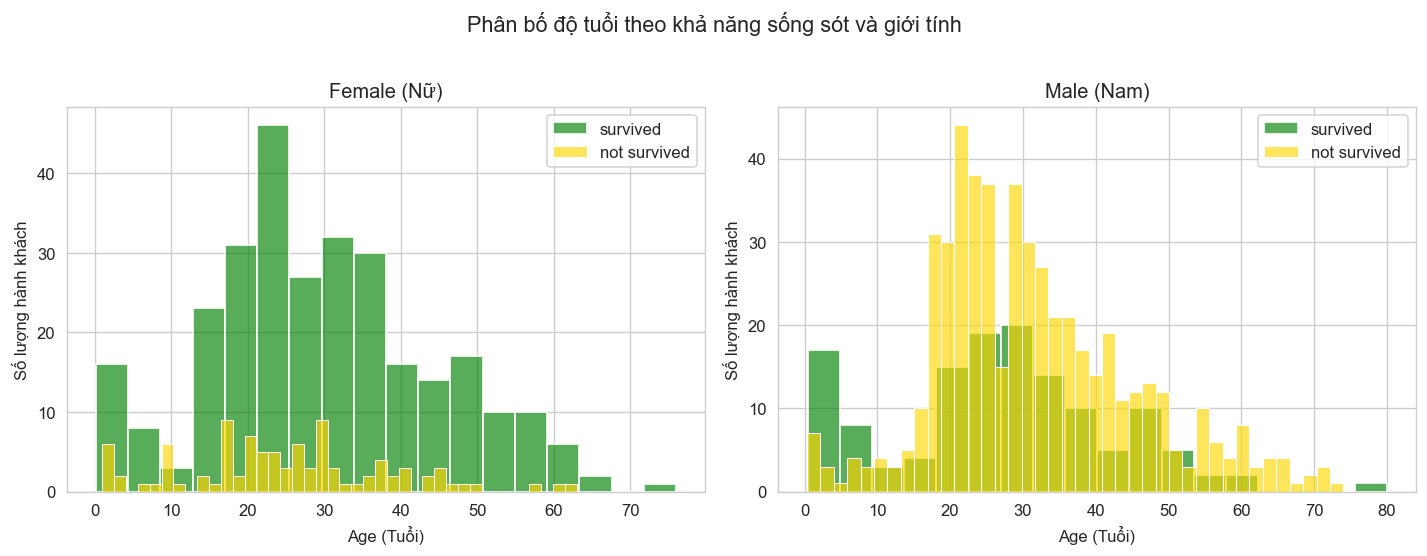

Tỷ lệ sống sót theo giới tính:


,Tổng,Sống sót,Tỷ lệ sống sót
sex,,,
female,466,339,0.727468
male,843,161,0.190985


In [5]:
print("Dương Đại Phát - 6451071058")
survived_label = "survived"
not_survived_label = "not survived"

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4.5))
women = df[df["sex"] == "female"]
men = df[df["sex"] == "male"]

sns.histplot(women[women["survived"] == 1]["age"].dropna(), bins=18, label=survived_label, ax=axes[0], kde=False, color="green", alpha=0.65)
sns.histplot(women[women["survived"] == 0]["age"].dropna(), bins=40, label=not_survived_label, ax=axes[0], kde=False, color="gold", alpha=0.65)
axes[0].legend()
axes[0].set_title("Female (Nữ)")
axes[0].set_xlabel("Age (Tuổi)")
axes[0].set_ylabel("Số lượng hành khách")

sns.histplot(men[men["survived"] == 1]["age"].dropna(), bins=18, label=survived_label, ax=axes[1], kde=False, color="green", alpha=0.65)
sns.histplot(men[men["survived"] == 0]["age"].dropna(), bins=40, label=not_survived_label, ax=axes[1], kde=False, color="gold", alpha=0.65)
axes[1].legend()
axes[1].set_title("Male (Nam)")
axes[1].set_xlabel("Age (Tuổi)")
axes[1].set_ylabel("Số lượng hành khách")

plt.suptitle("Phân bố độ tuổi theo khả năng sống sót và giới tính", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print("Tỷ lệ sống sót theo giới tính:")
display(df.groupby("sex")["survived"].agg(["count", "sum", "mean"]).rename(columns={"count": "Tổng", "sum": "Sống sót", "mean": "Tỷ lệ sống sót"}))

**Nhận xét (Yêu cầu 3):**
- **Giới tính ảnh hưởng rất mạnh đến khả năng sống sót**: Nữ giới có tỷ lệ sống sót **72,75%** (339/466), cao hơn gấp gần 4 lần so với nam giới là **19,10%** (161/843).
- Ở **nam giới**, nhóm trẻ em dưới 10 tuổi có tỷ lệ sống sót cao hơn rõ rệt so với nhóm thanh niên/trung niên (18–40 tuổi – nhóm có số lượng tử vong tập trung dày đặc nhất).
- Ở **nữ giới**, khả năng sống sót cao xuyên suốt hầu hết các độ tuổi, đặc biệt trong khoảng 15–40 tuổi.

## Yêu cầu 4: Khảo sát sự liên quan giữa Cổng lên tàu (`embarked`) và Loại vé (`pclass`) với khả năng sống sót (`survived`), phân biệt theo Giới tính (`sex`)

Dương Đại Phát - 6451071058


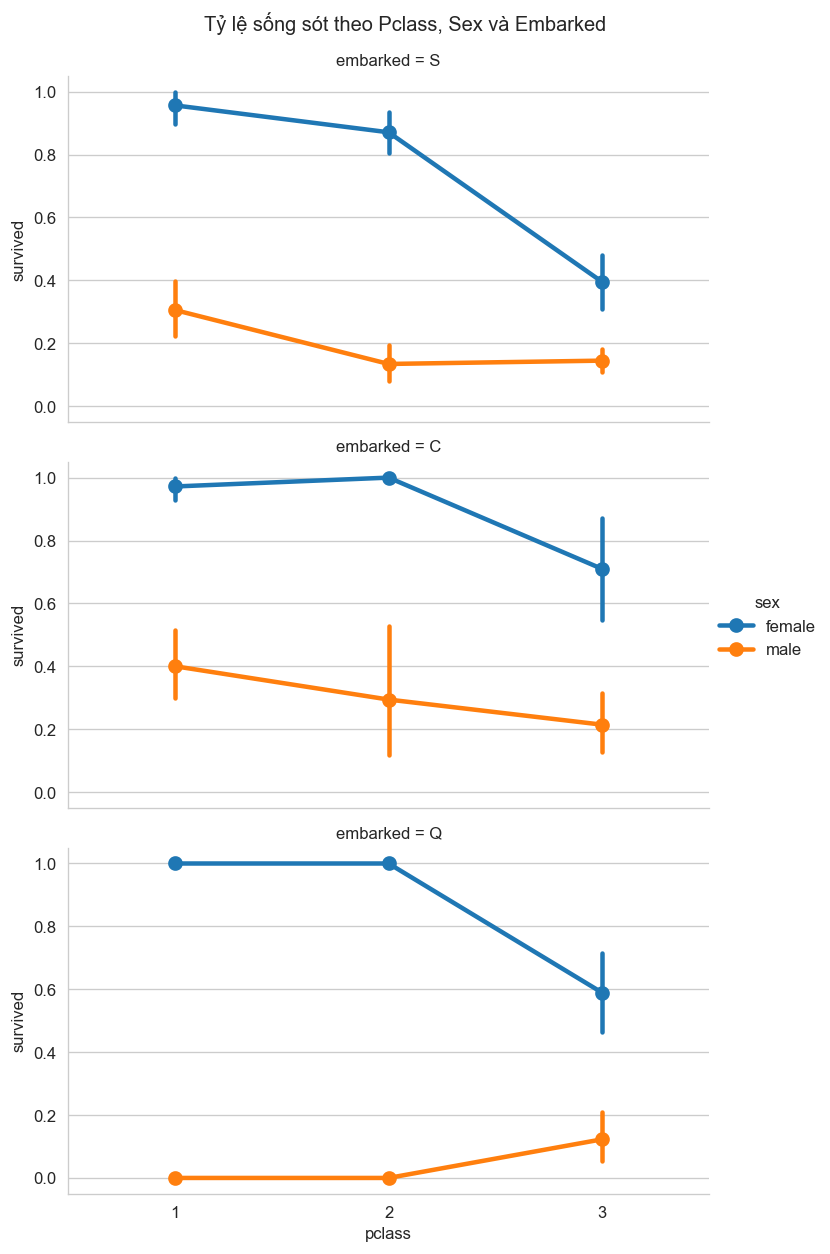

Bảng tỷ lệ sống sót theo Embarked, Pclass và Sex:


sex              female    male
embarked pclass                
C        1       0.9718  0.4000
         2       1.0000  0.2941
         3       0.7097  0.2143
Q        1       1.0000  0.0000
         2       1.0000  0.0000
         3       0.5893  0.1228
S        1       0.9565  0.3056
         2       0.8710  0.1342
         3       0.3953  0.1448

In [6]:
print("Dương Đại Phát - 6451071058")
g = sns.catplot(
    x="pclass",
    y="survived",
    hue="sex",
    row="embarked",
    data=df,
    kind="point",
    height=3.4,
    aspect=1.8,
    hue_order=["female", "male"],
    palette={"female": "tab:blue", "male": "tab:orange"},
)
g.fig.suptitle("Tỷ lệ sống sót theo Pclass, Sex và Embarked", y=1.02)
plt.show()

print("Bảng tỷ lệ sống sót theo Embarked, Pclass và Sex:")
display(df.groupby(["embarked", "pclass", "sex"])["survived"].mean().unstack().round(4))

Dương Đại Phát - 6451071058


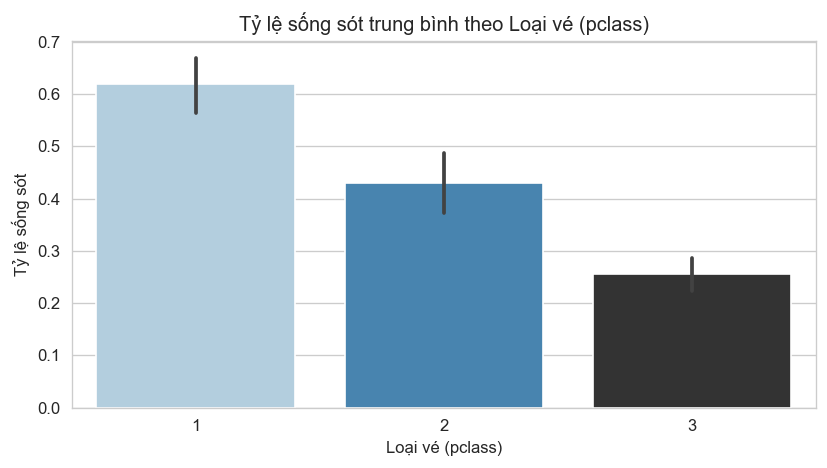

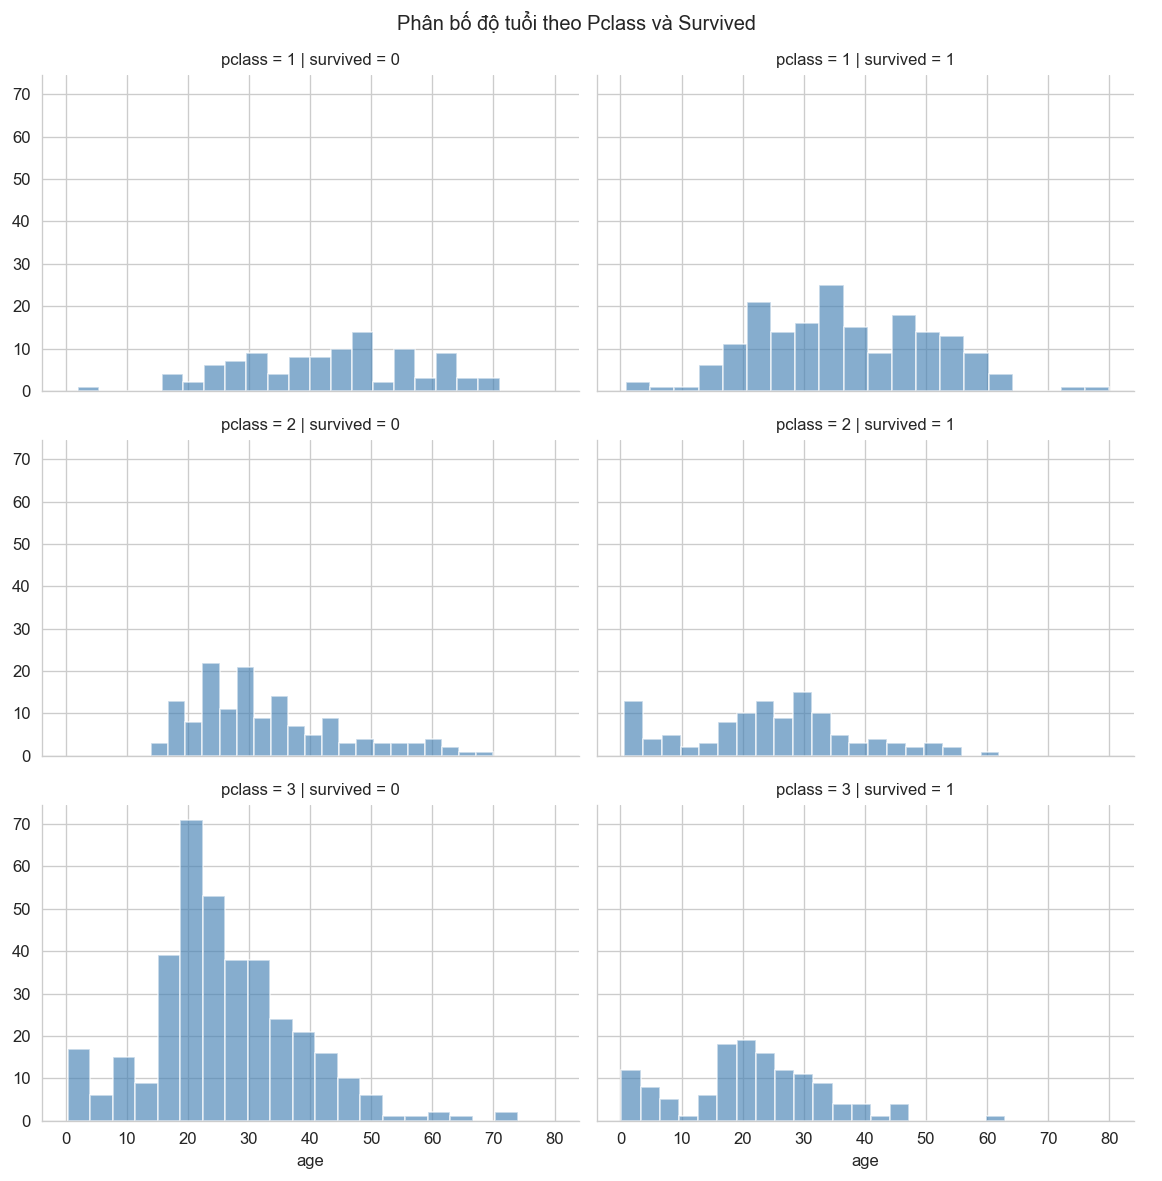

Tỷ lệ sống sót theo pclass:


,count,mean
pclass,,
1,323,0.6192
2,277,0.4296
3,709,0.2553


In [7]:
print("Dương Đại Phát - 6451071058")
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x="pclass", y="survived", data=df, ax=ax, palette="Blues_d", hue="pclass", legend=False)
ax.set_title("Tỷ lệ sống sót trung bình theo Loại vé (pclass)")
ax.set_xlabel("Loại vé (pclass)")
ax.set_ylabel("Tỷ lệ sống sót")
plt.tight_layout()
plt.show()

grid = sns.FacetGrid(df, col="survived", row="pclass", height=3.2, aspect=1.5)
grid.map(plt.hist, "age", alpha=0.65, bins=20, color="steelblue")
grid.add_legend()
grid.fig.suptitle("Phân bố độ tuổi theo Pclass và Survived", y=1.02)
plt.show()

print("Tỷ lệ sống sót theo pclass:")
display(df.groupby("pclass")["survived"].agg(["count", "mean"]).round(4))

**Nhận xét (Yêu cầu 4):**
- **Phân tích theo `embarked` và `sex`**:
  - Ở cả 3 cổng lên tàu (`C`, `Q`, `S`), **nữ giới** luôn có tỷ lệ sống sót cao vượt trội so với **nam giới** ở mọi hạng vé.
  - Hành khách lên tàu ở cổng **`C` (Cherbourg)** có tỷ lệ sống sót cao nhất cho cả hai giới (nữ hạng 1 đạt **97,18%**, hạng 2 đạt **100%**, hạng 3 đạt **70,97%**; nam hạng 1 đạt **40,00%**).
  - Ngược lại, nữ hạng 3 ở cổng **`S` (Southampton)** có tỷ lệ sống sót thấp nhất trong nhóm nữ (**39,53%**), và nam hạng 1/2 ở cổng **`Q` (Queenstown)** không có ai sống sót (**0%**).
- **Phân tích theo `pclass`**:
  - Hạng vé tỷ lệ thuận rõ rệt với khả năng sống sót: **Hạng 1 đạt 61,92%**, **Hạng 2 đạt 42,96%**, **Hạng 3 chỉ đạt 25,53%**.
  - Từ biểu đồ histogram `pclass` x `survived` theo `age`: số lượng người không sống sót tập trung rất lớn ở hành khách **hạng 3** trong độ tuổi **18–35**.

## Yêu cầu 5: Thống kê số người đi cùng (`relatives`, `not_alone`) và khảo sát sự liên quan với `survived`

Dương Đại Phát - 6451071058
Thống kê đi một mình (1) vs đi cùng người thân (0):


not_alone
Đi một mình (1)         790
Có người đi cùng (0)    519
Name: count, dtype: int64


Tỷ lệ sống sót theo số lượng người đi cùng (relatives):


,count,mean
relatives,,
0,790,0.3025
1,235,0.5362
2,159,0.5660
3,43,0.6977
4,22,0.2727
5,25,0.2000
6,16,0.2500
7,8,0.0000
10,11,0.0000


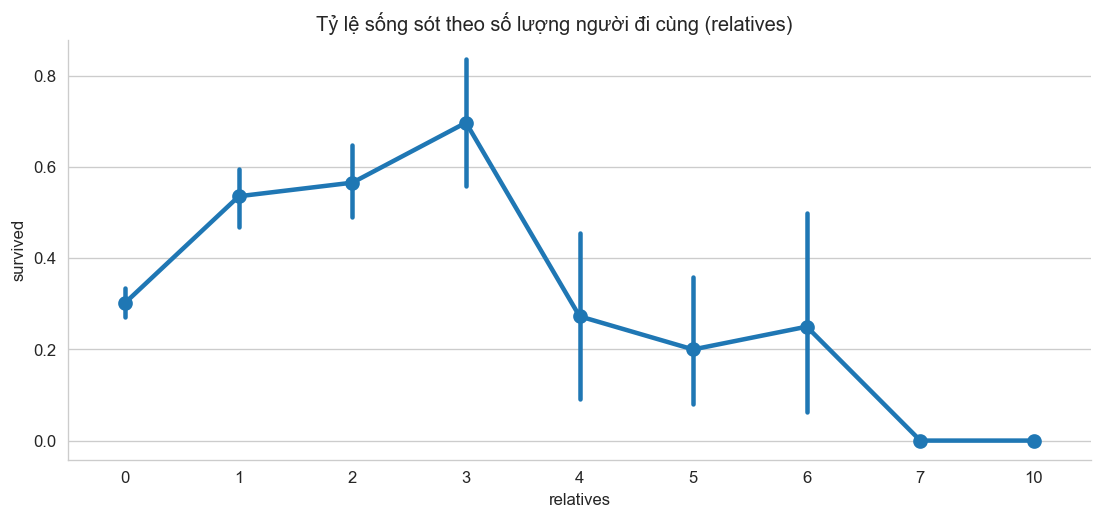

In [8]:
print("Dương Đại Phát - 6451071058")
df["relatives"] = df["sibsp"] + df["parch"]
df["not_alone"] = np.where(df["relatives"] > 0, 0, 1).astype(int)

print("Thống kê đi một mình (1) vs đi cùng người thân (0):")
display(df["not_alone"].value_counts().rename(index={1: "Đi một mình (1)", 0: "Có người đi cùng (0)"}))

print("\nTỷ lệ sống sót theo số lượng người đi cùng (relatives):")
display(df.groupby("relatives")["survived"].agg(["count", "mean"]).round(4))

g = sns.catplot(x="relatives", y="survived", data=df, kind="point", height=4.2, aspect=2.2)
g.fig.suptitle("Tỷ lệ sống sót theo số lượng người đi cùng (relatives)", y=1.02)
plt.show()

**Nhận xét (Yêu cầu 5):**
- Có **790 hành khách** đi một mình (`not_alone = 1`, tỷ lệ sống sót **30,25%**) và **519 hành khách** đi cùng người thân (`not_alone = 0`, tỷ lệ sống sót **50,29%**).
- Hành khách có **1 đến 3 người đi cùng** đạt tỷ lệ sống sót cao nhất (**53,62% – 69,77%**).
- Ngược lại, đi một mình (`relatives = 0`) hoặc đi nhóm gia đình quá đông (`relatives >= 4`) làm tỷ lệ sống sót giảm mạnh.

## Yêu cầu 6: Tiền xử lý các thuộc tính thiếu dữ liệu và xóa bỏ các thuộc tính không cần thiết

In [9]:
print("Dương Đại Phát - 6451071058")
np.random.seed(42)

# 1. Trích xuất thuộc tính deck từ cabin rồi xóa cabin
deck_map = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6, "G": 7, "U": 8}
df["cabin"] = df["cabin"].fillna("U0")
df["deck"] = df["cabin"].map(lambda x: re.compile(r"([a-zA-Z]+)").search(x).group())
df["deck"] = df["deck"].map(deck_map).fillna(0).astype(int)
df = df.drop(["cabin"], axis=1)

# 2. Xóa các thuộc tính không cần thiết / nhiều giá trị rỗng / gây rò rỉ nhãn (boat, body)
print("Thống kê sơ bộ ticket trước khi xóa:")
print(df["ticket"].describe())
df = df.drop(["ticket", "boat", "body", "home.dest"], axis=1)

# 3. Điền giá trị thiếu cho age bằng số nguyên ngẫu nhiên trong [mean - std, mean + std)
mean_age = df["age"].mean()
std_age = df["age"].std()
is_null_age = df["age"].isnull().sum()
rand_age = np.random.randint(int(mean_age - std_age), int(mean_age + std_age), size=is_null_age)
age_slice = df["age"].copy()
age_slice[age_slice.isnull()] = rand_age
df["age"] = age_slice.astype(int)

# 4. Điền giá trị thiếu cho embarked bằng giá trị xuất hiện nhiều nhất ('S')
common_embarked = df["embarked"].mode()[0]
print(f"Giá trị mode của embarked: {common_embarked}")
df["embarked"] = df["embarked"].fillna(common_embarked)

print("\nSố lượng giá trị rỗng còn lại sau Yêu cầu 6:")
display(df.isnull().sum())

Dương Đại Phát - 6451071058
Thống kê sơ bộ ticket trước khi xóa:
count         1309
unique         929
top       CA. 2343
freq            11
Name: ticket, dtype: object
Giá trị mode của embarked: S

Số lượng giá trị rỗng còn lại sau Yêu cầu 6:


pclass       0
survived     0
name         0
sex          0
age          0
sibsp        0
parch        0
fare         1
embarked     0
relatives    0
not_alone    0
deck         0
dtype: int64

**Nhận xét (Yêu cầu 6):**
- Từ `cabin` đã trích xuất được ký tự tầng boong (`deck` từ A–G mã hóa `1–7`, thiếu mã hóa `U -> 8`, chữ `T` hiếm -> `0`) trước khi xóa `cabin`.
- Đã loại bỏ `ticket`, `home.dest` (quá nhiều giá trị rời rạc/thiếu) và `boat`, `body` (tránh rò rỉ thông tin hậu sự cố).
- Đã điền **263** giá trị thiếu của `age` bằng phân bố ngẫu nhiên trong `[mean - std, mean + std)` và **2** giá trị thiếu của `embarked` bằng mode `'S'`. Hiện chỉ còn 1 giá trị rỗng ở `fare` sẽ được xử lý ở Yêu cầu 7.

## Yêu cầu 7: Biến đổi các thuộc tính (`fare`, `title`, `sex`, `embarked`, phân nhóm `age` và `fare`)

In [10]:
print("Dương Đại Phát - 6451071058")
# 1. Chuyển đổi fare về kiểu nguyên (sau khi điền 1 giá trị null bằng 0)
df["fare"] = df["fare"].fillna(0).astype(int)

# 2. Trích xuất danh hiệu (title) từ name bằng raw regex
titles_map = {"Mr": 1, "Miss": 2, "Mrs": 3, "Master": 4, "Rare": 5}
df["title"] = df["name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
df["title"] = df["title"].replace(
    ["Lady", "Countess", "Capt", "Col", "Don", "Dr", "Major", "Rev", "Sir", "Jonkheer", "Dona"],
    "Rare",
)
df["title"] = df["title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
df["title"] = df["title"].map(titles_map).fillna(0).astype(int)
df = df.drop(["name"], axis=1)

# 3. Chuyển đổi sex và embarked thành số
df["sex"] = df["sex"].map({"male": 0, "female": 1}).astype(int)
df["embarked"] = df["embarked"].map({"S": 0, "C": 1, "Q": 2}).astype(int)

# 4. Chia thuộc tính age thành 8 nhóm theo gợi ý
age_copy = df["age"].copy()
df.loc[age_copy <= 11, "age"] = 0
df.loc[(age_copy > 11) & (age_copy <= 18), "age"] = 1
df.loc[(age_copy > 18) & (age_copy <= 22), "age"] = 2
df.loc[(age_copy > 22) & (age_copy <= 27), "age"] = 3
df.loc[(age_copy > 27) & (age_copy <= 33), "age"] = 4
df.loc[(age_copy > 33) & (age_copy <= 40), "age"] = 5
df.loc[(age_copy > 40) & (age_copy <= 66), "age"] = 6
df.loc[age_copy > 66, "age"] = 7
df["age"] = df["age"].astype(int)

# 5. Chia thuộc tính fare thành 6 nhóm theo gợi ý
fare_copy = df["fare"].copy()
df.loc[fare_copy <= 7.91, "fare"] = 0
df.loc[(fare_copy > 7.91) & (fare_copy <= 14.454), "fare"] = 1
df.loc[(fare_copy > 14.454) & (fare_copy <= 31), "fare"] = 2
df.loc[(fare_copy > 31) & (fare_copy <= 99), "fare"] = 3
df.loc[(fare_copy > 99) & (fare_copy <= 250), "fare"] = 4
df.loc[fare_copy > 250, "fare"] = 5
df["fare"] = df["fare"].astype(int)

print("Phân bố 8 nhóm tuổi (0..7):")
display(df["age"].value_counts().sort_index())
print("Phân bố 6 nhóm giá vé (0..5):")
display(df["fare"].value_counts().sort_index())

Dương Đại Phát - 6451071058
Phân bố 8 nhóm tuổi (0..7):


age
0     91
1    144
2    176
3    214
4    224
5    202
6    249
7      9
Name: count, dtype: int64

Phân bố 6 nhóm giá vé (0..5):


fare
0    361
1    312
2    325
3    227
4     67
5     17
Name: count, dtype: int64

**Nhận xét (Yêu cầu 7):**
- Đã trích xuất danh hiệu (`Mr=1, Miss=2, Mrs=3, Master=4, Rare=5`), số hóa `sex` và `embarked`.
- Các nhóm `age` (`0–7`) và `fare` (`0–5`) đã được rời rạc hóa theo đúng ngưỡng gợi ý trong tài liệu, phân bố tương đối đồng đều ở các nhóm chính.

## Yêu cầu 8: Tạo các thuộc tính mới (`age_class`, `fare_per_person`)

In [11]:
print("Dương Đại Phát - 6451071058")
df["age_class"] = df["age"] * df["pclass"]
df["fare_per_person"] = (df["fare"] / (df["relatives"] + 1)).astype(int)

display(df.head(10))
print("\nThông tin tập dữ liệu hoàn chỉnh sau tiền xử lý:")
df.info()
print("\nTổng giá trị rỗng toàn bảng:", int(df.isnull().sum().sum()))

Dương Đại Phát - 6451071058


,pclass,survived,sex,age,sibsp,parch,fare,embarked,relatives,not_alone,deck,title,age_class,fare_per_person
0,1,1,1,4,0,0,4,0,0,1,2,2,4,4
1,1,1,0,0,1,2,4,0,3,0,3,4,0,1
2,1,0,1,0,1,2,4,0,3,0,3,2,0,1
3,1,0,0,4,1,2,4,0,3,0,3,1,4,1
4,1,0,1,3,1,2,4,0,3,0,3,3,3,1
5,1,1,0,6,0,0,2,0,0,1,5,1,6,2
6,1,1,1,6,1,0,3,0,1,0,4,2,6,1
7,1,0,0,5,0,0,0,0,0,1,1,1,5,0
8,1,1,1,6,2,0,3,0,2,0,3,3,6,1
9,1,0,0,7,0,0,3,1,0,1,8,1,7,3



Thông tin tập dữ liệu hoàn chỉnh sau tiền xử lý:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   pclass           1309 non-null   int64
 1   survived         1309 non-null   int64
 2   sex              1309 non-null   int64
 3   age              1309 non-null   int64
 4   sibsp            1309 non-null   int64
 5   parch            1309 non-null   int64
 6   fare             1309 non-null   int64
 7   embarked         1309 non-null   int64
 8   relatives        1309 non-null   int64
 9   not_alone        1309 non-null   int64
 10  deck             1309 non-null   int64
 11  title            1309 non-null   int64
 12  age_class        1309 non-null   int64
 13  fare_per_person  1309 non-null   int64
dtypes: int64(14)
memory usage: 143.3 KB

Tổng giá trị rỗng toàn bảng: 0


**Kết luận (Yêu cầu 8):**
- Đã tạo thành công hai thuộc tính tương tác mới là `age_class` (`age * pclass`) và `fare_per_person` (`fare / (relatives + 1)` làm tròn nguyên).
- Toàn bộ tập dữ liệu sau xử lý gồm **1.309 dòng x 14 cột số nguyên (`int64`)**, hoàn toàn không còn giá trị thiếu (`0` nulls), sẵn sàng cho các thuật toán học máy tiếp theo.